In [3]:
%pip install shap

  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Using cached cloudpickle-3.1.3-py3-none-any.whl (22 kB)

   ------------- -------------------------- 1/3 [cloudpickle]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("SHAP version:", shap.__version__)
print("Notebook working directory:", Path.cwd())

c:\Users\dvdsl\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1
Notebook working directory: c:\Users\dvdsl\OneDrive\Documents\GitHub\AI 311


In [5]:
# Find the AI 311 root whether VS Code starts in the root or notebooks/.
candidates = [Path.cwd(), Path.cwd().parent]
project_dir = next(
    (p for p in candidates if (p / "Data" / "processed").is_dir()),
    None
)
if project_dir is None:
    raise FileNotFoundError(
        "Cannot find Data/processed. Open the AI 311 folder in VS Code "
        "or set project_dir to its full path. Checked: " + str(candidates)
    )

model_path = project_dir / "Data" / "processed" / "final_phishing_model.pkl"
data_path = project_dir / "Data" / "processed" / "processed_data.pkl"
for p in (model_path, data_path):
    if not p.is_file():
        raise FileNotFoundError(f"Missing: {p}")
    with p.open("rb") as f:
        if f.read(40).startswith(b"version https://git-lfs.github.com"):
            raise ValueError(f"{p.name} is a Git LFS pointer; run 'git lfs pull'.")

with model_path.open("rb") as f:
    final_model = pickle.load(f)
with data_path.open("rb") as f:
    X_train, X_test, train_labels, test_labels, vectorizer = pickle.load(f)

print("Final model:", final_model)
print("Train data:", X_train.shape, "test data:", X_test.shape)
print("Train labels:", len(train_labels), "test labels:", len(test_labels))
print("TF-IDF features:", len(vectorizer.get_feature_names_out()))
assert X_train.shape[0] == len(train_labels), "Training rows and labels do not align."
assert X_test.shape[0] == len(test_labels), "Test rows and labels do not align."
assert final_model.n_features_in_ == X_test.shape[1], "Model and test matrix feature counts differ."
assert set(final_model.classes_) == {0, 1}, "Expected 0=legitimate and 1=phishing."
assert final_model.kernel == "linear", "These SHAP instructions require a linear-kernel SVC."
assert hasattr(final_model, "coef_"), "SVC linear coefficients not available."
print("Basic checks passed.")
print("IMPORTANT: Matching feature counts does not prove the model was trained with this exact fitted vectorizer.")

Final model: SVC(C=1, kernel='linear')
Train data: (65660, 5000) test data: (16416, 5000)
Train labels: 65660 test labels: 16416
TF-IDF features: 5000
Basic checks passed.
IMPORTANT: Matching feature counts does not prove the model was trained with this exact fitted vectorizer.


In [6]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.asarray(test_labels)
y_pred = final_model.predict(X_test)
scores = final_model.decision_function(X_test)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
print("Confusion matrix [legitimate, phishing]:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
print("False negatives:", fn, "| False positives:", fp)
print(classification_report(y_true, y_pred, target_names=["Legitimate", "Phishing"]))

results = pd.DataFrame({
    "actual": y_true,
    "predicted": y_pred,
    "decision_score": scores,
    "test_position": np.arange(len(y_true))
}, index=test_labels.index)

missed = results[(results.actual == 1) & (results.predicted == 0)]
flagged = results[(results.actual == 0) & (results.predicted == 1)]
display(missed.head(10))

Confusion matrix [legitimate, phishing]:
[[7787  123]
 [ 127 8379]]
False negatives: 127 | False positives: 123
              precision    recall  f1-score   support

  Legitimate       0.98      0.98      0.98      7910
    Phishing       0.99      0.99      0.99      8506

    accuracy                           0.98     16416
   macro avg       0.98      0.98      0.98     16416
weighted avg       0.98      0.98      0.98     16416



,actual,predicted,decision_score,test_position
81005,1,0,-1.166525,53
18139,1,0,-0.143166,95
20565,1,0,-2.158711,248
81929,1,0,-0.281136,267
17320,1,0,-0.196273,633
3548,1,0,-0.753200,690
18623,1,0,-0.340714,1031
18463,1,0,-2.146352,1032
26540,1,0,-0.092459,1068
17976,1,0,-0.027220,1077


In [7]:
# An SVC with a linear kernel exposes its sparse coefficient vector.
coef = final_model.coef_.toarray() if hasattr(final_model.coef_, "toarray") else np.asarray(final_model.coef_)
intercept = np.asarray(final_model.intercept_)
feature_names = vectorizer.get_feature_names_out()

# Check direction: binary SVC decision scores > 0 correspond to classes_[1].
print("Class order:", final_model.classes_)
assert final_model.classes_[1] == 1, "SHAP sign must be reinterpreted if class 1 isn't the positive class."

rng = np.random.default_rng(42)
bg_positions = rng.choice(X_train.shape[0], size=min(100, X_train.shape[0]), replace=False)
background = X_train[bg_positions]
masker = shap.maskers.Independent(background, max_samples=100)
explainer = shap.LinearExplainer((coef, intercept), masker)
print("SHAP explainer ready. Background rows:", background.shape[0])

Class order: [0 1]
SHAP explainer ready. Background rows: 100


Original dataframe index: 81005
Test matrix position: 53
Actual label: 1 Predicted: 0
SVM decision score: -1.1665254693694866
SHAP reconstruction: -1.1665254693694955
SVM decision score: -1.1665254693694866


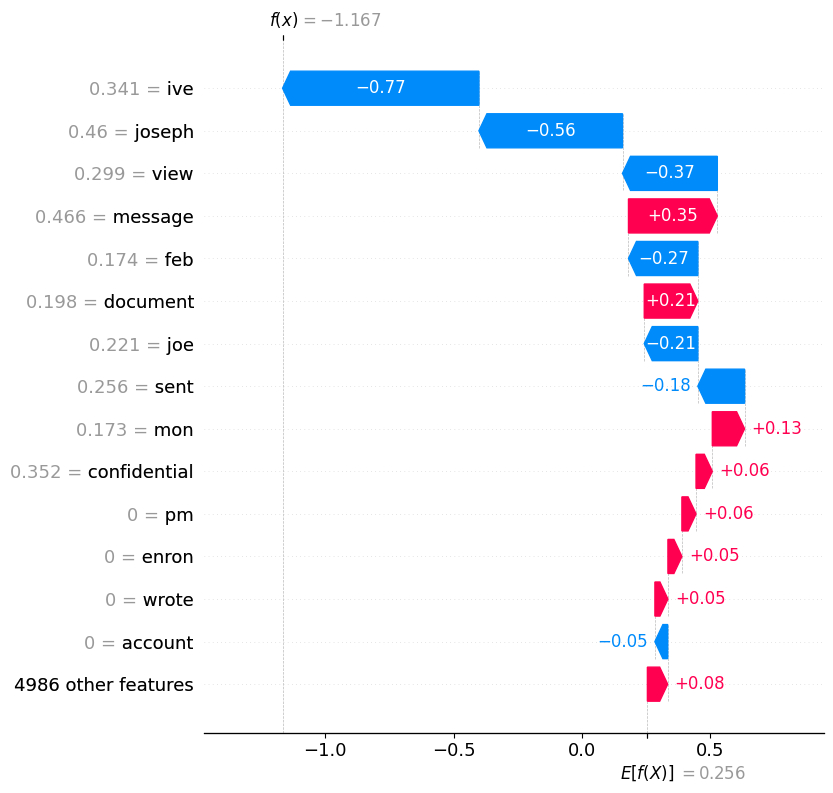

In [8]:
if len(missed) == 0:
    raise ValueError("No false negatives in this evaluation; select a different test row.")

position = int(missed.iloc[0]["test_position"])
row_index = results.index[position]
print("Original dataframe index:", row_index)
print("Test matrix position:", position)
print("Actual label:", y_true[position], "Predicted:", y_pred[position])
print("SVM decision score:", scores[position])

# Calculate SHAP for this one sparse TF-IDF row.
values = explainer(X_test[position:position+1])
shap_row = np.asarray(values.values[0]).reshape(-1)
base = float(np.asarray(values.base_values[0]).reshape(-1)[0])
row_features = X_test[position].toarray().reshape(-1)
print("SHAP reconstruction:", base + shap_row.sum())
print("SVM decision score:", scores[position])
assert np.isclose(base + shap_row.sum(), scores[position], atol=1e-5),     "SHAP values do not reconstruct the SVM decision score."

single_explanation = shap.Explanation(
    values=shap_row,
    base_values=base,
    data=row_features,
    feature_names=feature_names
)
shap.plots.waterfall(single_explanation, max_display=15)
plt.show()

In [9]:
present = row_features > 0
feature_effects = pd.DataFrame({
    "feature": feature_names,
    "tfidf_value": row_features,
    "shap_contribution": shap_row
})
present_effects = feature_effects[present].copy()

print("Top PRESENT features pushing toward phishing (+):")
display(present_effects.sort_values("shap_contribution", ascending=False).head(10))
print("Top PRESENT features pushing toward legitimate (-):")
display(present_effects.sort_values("shap_contribution", ascending=True).head(10))
print("Positive = pushes SVM score toward phishing; negative = toward legitimate.")

Top PRESENT features pushing toward phishing (+):


,feature,tfidf_value,shap_contribution
2794,message,0.465858,0.346449
1299,document,0.198093,0.209024
2875,mon,0.172614,0.125912
898,confidential,0.351995,0.063425
3828,review,0.165569,0.003816
4006,sent,0.256256,-0.182369
2378,joe,0.220944,-0.208921
1699,feb,0.174023,-0.270539
4787,view,0.299360,-0.369741
2392,joseph,0.460495,-0.559870


Top PRESENT features pushing toward legitimate (-):


,feature,tfidf_value,shap_contribution
2346,ive,0.340863,-0.765565
2392,joseph,0.460495,-0.559870
4787,view,0.299360,-0.369741
1699,feb,0.174023,-0.270539
2378,joe,0.220944,-0.208921
4006,sent,0.256256,-0.182369
3828,review,0.165569,0.003816
898,confidential,0.351995,0.063425
2875,mon,0.172614,0.125912
1299,document,0.198093,0.209024


Positive = pushes SVM score toward phishing; negative = toward legitimate.


,feature,mean_absolute_shap,mean_signed_shap
3346,pm,0.105349,-0.006097
1798,fork,0.100302,-0.092797
3926,savings,0.068228,-0.068228
4961,wrote,0.066714,0.029742
2566,linguistics,0.060840,-0.053766
2858,mobile,0.056884,0.048660
1481,enron,0.054486,0.054486
4396,syntax,0.050630,-0.029962
31,account,0.049853,-0.049853
2346,ive,0.048267,-0.028290


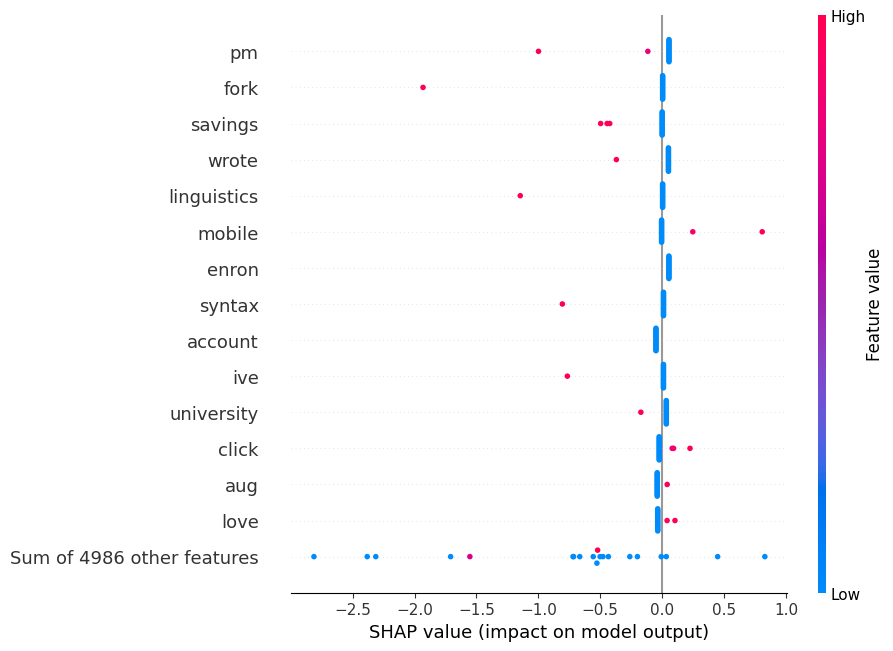

In [10]:
n_cases = min(20, len(missed))
positions = missed["test_position"].iloc[:n_cases].to_numpy(dtype=int)
case_matrix = X_test[positions]
case_shap = explainer(case_matrix)

case_values = np.asarray(case_shap.values).reshape(n_cases, -1)
importance = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": np.abs(case_values).mean(axis=0),
    "mean_signed_shap": case_values.mean(axis=0)
}).sort_values("mean_absolute_shap", ascending=False)

display(importance.head(20))

case_explanation = shap.Explanation(
    values=case_values,
    base_values=np.asarray(case_shap.base_values).reshape(n_cases, -1)[:, 0],
    data=case_matrix.toarray(),
    feature_names=feature_names
)
shap.plots.beeswarm(case_explanation, max_display=15)
plt.show()

In [11]:
csv_path = project_dir / "Data" / "processed" / "phishing_email_data_main.csv"
if not csv_path.exists():
    print("Original CSV not found at:", csv_path)
else:
    original_df = pd.read_csv(csv_path)
    idx = int(row_index)
    if ("label" not in original_df.columns or idx >= len(original_df)
            or int(original_df.iloc[idx]["label"]) != int(y_true[position])):
        print("Could not verify the original row's label; do not use this CSV to interpret this case.")
    else:
        print("Row label matches. Also verify the dataset has not been reordered.")
        text_col = next((c for c in ["text_combined", "Cleaned_text"] if c in original_df.columns), None)
        if text_col:
            print("Original index:", idx, "| Column:", text_col)
            print(str(original_df.iloc[idx][text_col])[:3000])
        else:
            print("Available columns:", original_df.columns.tolist())

Row label matches. Also verify the dataset has not been reordered.
Original index: 81005 | Column: Cleaned_text
joe aloisa aloisaaolcom ive sent confidential message view message joseph aloisa ive sent confidential message view message joseph aloisa mon  feb    review document
